<center><h1>Xia_Zihan_HW7</h1></center>
<br>
<br>

Name: Zihan Xia
<br>
Github Username: ZoeCreates
<br>
USC ID: 5179148878

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

RNG = 42

### (a) Download the data and choose 70% as the training set
The 22 MFCC columns are the features. `RecordID` is not a feature, so I drop it. The split is random (seed 42).

In [2]:
df = pd.read_csv("Frogs_MFCCs.csv")
feats = [c for c in df.columns if c.startswith("MFCCs")]
labels = ["Family", "Genus", "Species"]
X = df[feats].to_numpy()
Y = df[labels].to_numpy(dtype=object)
Xtr, Xte, Ytr, Yte = train_test_split(X, Y, train_size=0.7, random_state=RNG)
print("all:", X.shape, "| train:", Xtr.shape, "| test:", Xte.shape)
for j, lab in enumerate(labels):
    print(f"{lab}: {len(np.unique(Y[:, j]))} classes")

all: (7195, 22) | train: (5036, 22) | test: (2159, 22)
Family: 4 classes
Genus: 8 classes
Species: 10 classes


### (b) Binary relevance: one classifier for each label

#### (i) Exact match and Hamming score / loss
For $n$ instances and $L = 3$ labels, let $y_{ij}$ be the true value of label $j$ for instance $i$ and $\hat y_{ij}$ the prediction.

- **Exact match ratio**: the fraction of instances where *all* labels are right,
  $\frac{1}{n}\sum_i 1[\hat y_{i1} = y_{i1}, \dots, \hat y_{iL} = y_{iL}]$. It is the strictest measure: one wrong label makes the
  whole instance wrong.
- **Hamming loss**: the fraction of individual labels that are wrong, $\frac{1}{nL}\sum_i \sum_j 1[\hat y_{ij} \neq y_{ij}]$.
  Lower is better. It gives partial credit when only some labels are wrong.
- **Hamming score**: $1 - $ Hamming loss, i.e. the fraction of labels that are right.

Sorower's survey also defines a set-based "Hamming score" (accuracy) as $\frac{1}{n}\sum_i \frac{|Y_i \cap \hat Y_i|}{|Y_i \cup \hat Y_i|}$.
Here every instance has exactly one family, one genus and one species, so if $m$ of the 3 labels are right this equals $m / (6 - m)$.
I report it too, as "Jaccard score".

In [3]:
def multilabel_scores(Y_true, Y_pred):
    wrong = (Y_true != Y_pred)
    m = (~wrong).sum(axis=1)                     # number of correct labels per instance
    return {"exact match": (~wrong.any(axis=1)).mean(),
            "Hamming loss": wrong.mean(),
            "Hamming score": 1 - wrong.mean(),
            "Jaccard score": (m / (6 - m)).mean()}

cv10 = StratifiedKFold(10, shuffle=True, random_state=RNG)
summary = {}

def fit_per_label(make_model, grid, name):
    """10-fold CV grid search for each label, then predict the test set."""
    t = time.time()
    models, rows = {}, []
    Y_pred = np.empty_like(Yte)
    for j, lab in enumerate(labels):
        gs = GridSearchCV(make_model(), grid, cv=cv10, n_jobs=-1).fit(Xtr, Ytr[:, j])
        models[lab] = gs
        Y_pred[:, j] = gs.predict(Xte)
        rows.append({"label": lab, **{k.split("__")[-1]: v for k, v in gs.best_params_.items()},
                     "CV accuracy": gs.best_score_,
                     "test accuracy": accuracy_score(Yte[:, j], Y_pred[:, j]),
                     "test balanced acc.": balanced_accuracy_score(Yte[:, j], Y_pred[:, j])})
    tab = pd.DataFrame(rows)
    if "gamma" in tab:
        tab.insert(tab.columns.get_loc("gamma") + 1, "sigma", np.sqrt(1 / (2 * tab["gamma"])))
    print(f"{name}  ({time.time() - t:.0f} s)")
    print(tab.round(4).to_string(index=False))
    scores = multilabel_scores(Yte, Y_pred)
    summary[name] = scores
    print("test set:", ", ".join(f"{k} = {v:.4f}" for k, v in scores.items()))
    return models, Y_pred

#### (ii) SVM with a Gaussian kernel, one versus all
`OneVsRestClassifier(SVC(kernel="rbf"))` trains one binary SVM per class. The kernel is
$K(x, x') = \exp(-\|x - x'\|^2 / (2\sigma^2))$, so `gamma` $= 1/(2\sigma^2)$.

**Choosing the ranges (footnote 1).** I first trained a few models on the whole training set for Species. With $C = 0.01$ the
training accuracy drops below 70% for $\sigma = 0.1$ and $\sigma = 3$, while $C \ge 1$ stays above 70%. Very small $\sigma$
(0.1) overfits (training accuracy 1.0, test about 0.89) and is very slow. So I search $C \in \{1, 10, 10^2, 10^3, 10^4\}$
(steps in $\log C$) and $\sigma \in \{0.5, 1, 1.5, 2\}$.

For the standardized features each column has variance 1 instead of a range of about $[-1, 1]$, so the distances between
points are several times larger. I scale the $\sigma$ grid up accordingly: $\sigma \in \{2, 3, 4, 6\}$. The scaler is inside the
pipeline, so it is refit on the training part of each CV fold.

In [4]:
C_rbf = [1, 10, 100, 1000, 10000]
sig_raw = [0.5, 1, 1.5, 2]
sig_std = [2, 3, 4, 6]
gam = lambda sigmas: [1 / (2 * s ** 2) for s in sigmas]

rbf_raw, pred_rbf_raw = fit_per_label(
    lambda: OneVsRestClassifier(SVC(kernel="rbf")),
    {"estimator__C": C_rbf, "estimator__gamma": gam(sig_raw)}, "Gaussian SVM (raw)")

Gaussian SVM (raw)  (17 s)
  label   C  gamma  sigma  CV accuracy  test accuracy  test balanced acc.
 Family 100    2.0    0.5       0.9927         0.9954              0.9782
  Genus  10    2.0    0.5       0.9915         0.9907              0.9599
Species 100    2.0    0.5       0.9911         0.9912              0.9693
test set: exact match = 0.9889, Hamming loss = 0.0076, Hamming score = 0.9924, Jaccard score = 0.9913


In [5]:
rbf_std, pred_rbf_std = fit_per_label(
    lambda: Pipeline([("sc", StandardScaler()), ("svm", OneVsRestClassifier(SVC(kernel="rbf")))]),
    {"svm__estimator__C": C_rbf, "svm__estimator__gamma": gam(sig_std)}, "Gaussian SVM (standardized)")

Gaussian SVM (standardized)  (18 s)
  label   C  gamma  sigma  CV accuracy  test accuracy  test balanced acc.
 Family 100 0.0556    3.0       0.9921         0.9940              0.9788
  Genus  10 0.0556    3.0       0.9919         0.9880              0.9497
Species  10 0.0556    3.0       0.9909         0.9875              0.9561
test set: exact match = 0.9866, Hamming loss = 0.0102, Hamming score = 0.9898, Jaccard score = 0.9887


**Results.**
- With the raw features all three labels pick $\sigma = 0.5$, and $C = 100$ (Family, Species) or $C = 10$ (Genus). The CV accuracy is
  about 0.991-0.993, and on the test set the exact match is 0.9889 and the Hamming loss 0.0076.
- $\sigma = 0.5$ is the edge of my grid, so I also checked $\sigma = 0.3$ and $0.4$ separately with $C \in \{10, 100, 1000\}$. The CV
  accuracy changed by at most 0.0004 (one or two training points), and $\sigma = 0.3$ was worse for all labels. So the best $\sigma$ is
  around 0.4-0.5 and extending the grid would not change the results.
- With standardized features the best $\sigma$ is 3 and the test results are a little worse (exact match 0.9866, Hamming loss 0.0102).
  The MFCCs are already scaled to $[-1, 1]$ (footnote 2), so standardizing does not help here.
- The test balanced accuracy (0.95-0.98) is lower than the accuracy (about 0.99), so most of the few errors are on the small classes.

#### (iii) L1-penalized SVM
Following footnote 3, this is a linear SVM with an L1 penalty (`LinearSVC(penalty="l1", dual=False)`), which is one versus rest
by default. The features are standardized inside the pipeline. $C$ is chosen by 10-fold CV from 13 values between $10^{-3}$
and $10^{3}$.

In [6]:
C_l1 = np.logspace(-3, 3, 13)
l1_svm, pred_l1 = fit_per_label(
    lambda: Pipeline([("sc", StandardScaler()),
                      ("svm", LinearSVC(penalty="l1", dual=False, max_iter=20000, random_state=RNG))]),
    {"svm__C": C_l1}, "L1 SVM")

for lab in labels:
    coef = l1_svm[lab].best_estimator_.named_steps["svm"].coef_
    print(f"{lab}: {(coef == 0).mean():.0%} of the coefficients are exactly 0")

L1 SVM  (37 s)
  label        C  CV accuracy  test accuracy  test balanced acc.
 Family  10.0000       0.9412         0.9282              0.6902
  Genus 316.2278       0.9517         0.9416              0.7690
Species  10.0000       0.9607         0.9592              0.8948
test set: exact match = 0.9125, Hamming loss = 0.0570, Hamming score = 0.9430, Jaccard score = 0.9342
Family: 0% of the coefficients are exactly 0
Genus: 0% of the coefficients are exactly 0
Species: 0% of the coefficients are exactly 0


**Results.**
- The test exact match drops to 0.9125 and the Hamming loss rises to 0.0570, much worse than the Gaussian SVM.
  A linear boundary cannot separate the classes as well as the Gaussian kernel can.
- CV picks a fairly large $C$ (10 to 316), i.e. a weak penalty, and **none** of the coefficients are exactly 0. All 22 MFCCs seem to
  be useful, so the L1 penalty does not remove features here.
- Species (test accuracy 0.959) is easier than Family (0.928) for the linear model. This is probably because a family is a union of
  several species, which can make the family regions harder to separate with straight lines.
- The balanced accuracy is low, especially for Family (0.690) and Genus (0.769): the linear SVM often misses the small classes
  (e.g. Bufonidae, with 68 samples in the whole data set).

#### (iv) L1-penalized SVM with SMOTE
SMOTE creates synthetic samples for every minority class until each class has as many samples as the largest one.
It is placed inside the pipeline (scaler → SMOTE → L1 SVM), so in cross-validation SMOTE only sees the training part of each fold
and the validation fold has no synthetic points. The test set is never resampled.

In [7]:
l1_smote, pred_smote = fit_per_label(
    lambda: ImbPipeline([("sc", StandardScaler()), ("smote", SMOTE(random_state=RNG)),
                         ("svm", LinearSVC(penalty="l1", dual=False, max_iter=20000, random_state=RNG))]),
    {"svm__C": C_l1}, "L1 SVM + SMOTE")

L1 SVM + SMOTE  (287 s)
  label      C  CV accuracy  test accuracy  test balanced acc.
 Family 3.1623       0.9232         0.9092              0.9131
  Genus 1.0000       0.9128         0.9023              0.9162
Species 3.1623       0.9581         0.9579              0.9276
test set: exact match = 0.8536, Hamming loss = 0.0769, Hamming score = 0.9231, Jaccard score = 0.9040


In [8]:
print("Test set, all classifiers")
print(pd.DataFrame(summary).T.round(4).to_string())

Test set, all classifiers
                             exact match  Hamming loss  Hamming score  Jaccard score
Gaussian SVM (raw)                0.9889        0.0076         0.9924         0.9913
Gaussian SVM (standardized)       0.9866        0.0102         0.9898         0.9887
L1 SVM                            0.9125        0.0570         0.9430         0.9342
L1 SVM + SMOTE                    0.8536        0.0769         0.9231         0.9040


**Results and conclusions.**
- SMOTE clearly helps the small classes. The test balanced accuracy goes up from 0.690 to 0.913 (Family), from 0.769 to 0.916 (Genus)
  and from 0.895 to 0.928 (Species).
- The price is a lower overall accuracy for Family (0.928 to 0.909) and Genus (0.942 to 0.902), because more samples of the large
  classes are now assigned to the small ones. The exact match drops from 0.9125 to 0.8536 and the Hamming loss rises from 0.0570
  to 0.0769. Exact match and Hamming loss weight every instance equally, so they mostly reflect the large classes.
- Overall, the **Gaussian-kernel SVM on the raw features is by far the best classifier** (exact match 0.989, Hamming loss 0.008).
  Even without any imbalance correction its balanced accuracy is 0.96-0.98, so the imbalance is mainly a problem for the linear model.
- Whether SMOTE is worth it depends on the goal: if recognizing the rare frogs matters, the SMOTE model is better than the plain
  L1 SVM; if we only care about the overall number of correct labels, it is worse.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Choosing k with the silhouette
The whole data set is used (no split). In each Monte-Carlo run I fit k-means for every $k \in \{2, \dots, 50\}$ and pick the
$k$ with the highest average silhouette. ($k = 1$ is left out because the silhouette is not defined for a single cluster.)
To keep the run time reasonable, each silhouette is computed on a random sample of 2,000 points, and k-means uses one random
initialization per $k$; the 50 runs differ in their random seed. I also tried the CH index, but it picked $k = 2$, the smallest
possible value, in every test run, so I use the silhouette.

run 0: best k = 4 (4 s per run)


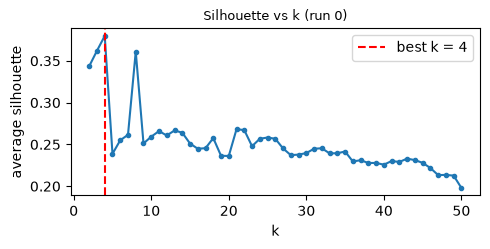

In [9]:
def run_once(seed, ks=range(2, 51)):
    best = (-1, None, None)
    sils = []
    for k in ks:
        lab = KMeans(k, n_init=1, random_state=seed).fit_predict(X)
        s = silhouette_score(X, lab, sample_size=2000, random_state=seed)
        sils.append(s)
        if s > best[0]:
            best = (s, k, lab)
    return best[1], best[2], sils

def majority_labels(clusters):
    """(b) majority family, genus and species in every cluster."""
    tab = pd.DataFrame(Y, columns=labels).assign(cluster=clusters)
    return tab.groupby("cluster")[labels].agg(lambda s: s.value_counts().idxmax())

def hamming(clusters):
    """(c) compare each point's true labels with the majority triplet of its cluster."""
    Y_hat = majority_labels(clusters).loc[clusters].to_numpy(dtype=object)
    wrong = (Y != Y_hat)
    return {"Hamming distance": wrong.sum(axis=1).mean(), "Hamming loss": wrong.mean(), "Hamming score": 1 - wrong.mean()}

t = time.time()
k0, clusters0, sils0 = run_once(0)
print("run 0: best k = %d (%.0f s per run)" % (k0, time.time() - t))
plt.figure(figsize=(5, 2.6))
plt.plot(range(2, 51), sils0, marker=".")
plt.axvline(k0, color="r", ls="--", label=f"best k = {k0}")
plt.xlabel("k"); plt.ylabel("average silhouette"); plt.legend(); plt.title("Silhouette vs k (run 0)", fontsize=9)
plt.tight_layout(); plt.savefig("q2_silhouette.png", dpi=110); plt.show()

### (b) Majority family, genus and species in each cluster (run 0)

In [10]:
maj0 = majority_labels(clusters0)
maj0["size"] = pd.Series(clusters0).value_counts().sort_index()
print(maj0.to_string())

                  Family      Genus                 Species  size
cluster                                                          
0        Leptodactylidae  Adenomera  AdenomeraHylaedactylus  3584
1                Hylidae  Hypsiboas       HypsiboasCordobae  2216
2                Hylidae  Hypsiboas    HypsiboasCinerascens   663
3        Leptodactylidae  Adenomera          AdenomeraAndre   732


### (c) Hamming distance, score and loss: 50 Monte-Carlo runs

In [11]:
t = time.time()
runs = []
for seed in range(50):
    k, clusters, _ = (k0, clusters0, None) if seed == 0 else run_once(seed)
    runs.append({"seed": seed, "k": k, **hamming(clusters)})
runs = pd.DataFrame(runs)
print("total time: %.0f s" % (time.time() - t))
print("chosen k:", runs["k"].value_counts().sort_index().to_dict())
print(runs[["Hamming distance", "Hamming loss", "Hamming score"]].agg(["mean", "std"]).round(4).to_string())

total time: 197 s
chosen k: {2: 6, 3: 14, 4: 24, 5: 1, 6: 5}
      Hamming distance  Hamming loss  Hamming score
mean            0.7249        0.2416         0.7584
std             0.1268        0.0423         0.0423


**Results.**
- The silhouette usually prefers a small number of clusters. Over the 50 runs it chose $k = 4$ in 24 runs, $k = 3$ in 14 runs,
  $k = 2$ in 6 runs, $k = 6$ in 5 runs and $k = 5$ in one run. In run 0 the curve peaks at $k = 4$ (0.38), with a second peak at $k = 8$.
- In run 0 the four clusters follow the four largest species (AdenomeraHylaedactylus, HypsiboasCordobae, AdenomeraAndre,
  HypsiboasCinerascens). Only 2 of the 4 families and 4 of the 10 species are ever a majority, so the small classes are always wrong.
- Over the 50 runs the average **Hamming distance is 0.725 (std 0.127)**: on average about 0.7 of the 3 labels of a call is wrong.
  The **Hamming loss is 0.242 (std 0.042)** and the **Hamming score 0.758 (std 0.042)**. The std comes mostly from the different $k$
  chosen in different runs.
- This is much worse than the SVMs in Question 1, which is expected: k-means never sees the labels, and the silhouette favors a few
  large, well-separated groups rather than one cluster per species.

## 3. ISLR 12.6.2
Dissimilarity matrix of four observations:

| | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| 1 | | 0.3 | 0.4 | 0.7 |
| 2 | 0.3 | | 0.5 | 0.8 |
| 3 | 0.4 | 0.5 | | 0.45 |
| 4 | 0.7 | 0.8 | 0.45 | |

**(a) Complete linkage.** The smallest dissimilarity is 0.3, so 1 and 2 fuse at height 0.3. Then
$d(\{1,2\}, 3) = \max(0.4, 0.5) = 0.5$, $d(\{1,2\}, 4) = \max(0.7, 0.8) = 0.8$ and $d(3, 4) = 0.45$, so 3 and 4 fuse at 0.45.
Finally $d(\{1,2\}, \{3,4\}) = \max(0.4, 0.5, 0.7, 0.8) = 0.8$, so the two clusters fuse at 0.8.

**(b) Single linkage.** 1 and 2 fuse at 0.3. Then $d(\{1,2\}, 3) = \min(0.4, 0.5) = 0.4$, $d(\{1,2\}, 4) = \min(0.7, 0.8) = 0.7$
and $d(3, 4) = 0.45$, so 3 joins $\{1,2\}$ at 0.4. Finally $d(\{1,2,3\}, 4) = \min(0.7, 0.8, 0.45) = 0.45$, so 4 joins at 0.45.

**(c)** Cutting the complete linkage dendrogram into two clusters gives **$\{1, 2\}$ and $\{3, 4\}$**.

**(d)** Cutting the single linkage dendrogram into two clusters gives **$\{1, 2, 3\}$ and $\{4\}$**.

**(e)** At each fusion the two branches can be swapped without changing the tree. For example, drawing the leaves of (a) in the
order 2, 1, 4, 3 (swap 1 with 2, and 3 with 4) gives the same dendrogram.

The code below checks the fusion heights with `scipy` and draws the three dendrograms.

complete linkage fusion heights: [0.3, 0.45, 0.8]


single linkage fusion heights: [0.3, 0.4, 0.45]
(a) leaf order: ['1', '2', '3', '4'] -> (e) leaf order: ['2', '1', '4', '3']


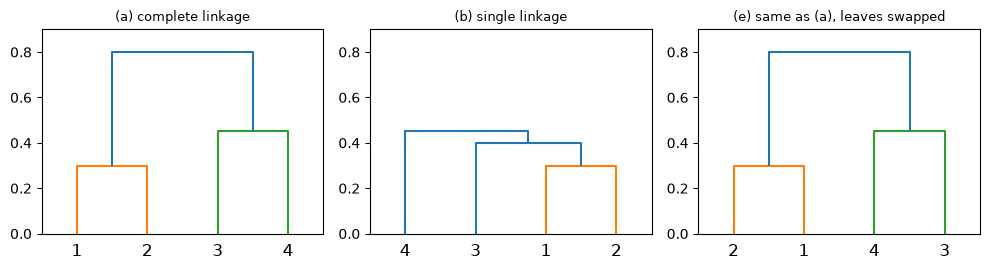

In [12]:
D = np.array([[0, 0.3, 0.4, 0.7],
              [0.3, 0, 0.5, 0.8],
              [0.4, 0.5, 0, 0.45],
              [0.7, 0.8, 0.45, 0]])
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, method, title in [(axes[0], "complete", "(a) complete linkage"), (axes[1], "single", "(b) single linkage")]:
    Z = linkage(squareform(D), method=method)
    print(method, "linkage fusion heights:", Z[:, 2].tolist())
    dendrogram(Z, labels=["1", "2", "3", "4"], ax=ax)
    ax.set_title(title, fontsize=9); ax.set_ylim(0, 0.9)
Z = linkage(squareform(D), method="complete")
leaves = dendrogram(Z, labels=["1", "2", "3", "4"], ax=axes[2])["ivl"]
# leaves 0-1 and 2-3 are the two pairs fused first, so swapping inside each pair draws the same tree
axes[2].set_xticklabels([leaves[1], leaves[0], leaves[3], leaves[2]])
print("(a) leaf order:", leaves, "-> (e) leaf order:", [leaves[1], leaves[0], leaves[3], leaves[2]])
axes[2].set_title("(e) same as (a), leaves swapped", fontsize=9); axes[2].set_ylim(0, 0.9)
plt.tight_layout(); plt.savefig("q3_dendrograms.png", dpi=110); plt.show()